In [ ]:
!unzip /content/Cyanobacteria.zip -d /content/PPI

unzip:  cannot find or open /content/Cyanobacteria.zip, /content/Cyanobacteria.zip.zip or /content/Cyanobacteria.zip.ZIP.


## IntAct

In [ ]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
# Lista de tus archivos MITAB descargados de IntAct
archivos_mitab = ["/content/PPI/Cyanobacteria.txt"]  # Cambia por tus rutas

organismos_interactores = {}
interactor_a_taxid = {}
interactor_a_organismo = {}  # NUEVO: Diccionario para guardar el organismo completo de cada proteína
organismos_interacciones = (
    {}
)  # Guardará las interacciones binarias con sus pesos

# ==========================================
# PASO 1 y 2: Procesar archivos MITAB
# ==========================================
for archivo in archivos_mitab:
  try:
    with open(archivo, "r", encoding="utf-8") as f:
      for line in f:
        # Saltar líneas de cabecera o comentarios
        if line.startswith("#"):
          continue

        cols = line.strip().split("\t")
        if len(cols) < 12:
          continue

        # 1. Obtener IDs de los interactores (Columna 0 y 1)
        id_a = cols[0]
        id_b = cols[1]

        # 2. Obtener Taxonomy IDs y descripciones (Columna 9 y 10)
        tax_a_raw = cols[9]
        tax_b_raw = cols[10]


        def extraer_taxid(tax_str):
          if "taxid:" in tax_str:
            try:
              return tax_str.split("taxid:")[1].split("(")[0]
            except:
              return "Desconocido"
          return "Desconocido"


        tax_id_a = extraer_taxid(tax_a_raw)
        tax_id_b = extraer_taxid(tax_b_raw)

        # Mapeos auxiliares
        interactor_a_taxid[id_a] = tax_id_a
        interactor_a_taxid[id_b] = tax_id_b

        # Guardar el texto completo del organismo para imprimirlo bonito
        interactor_a_organismo[id_a] = tax_a_raw
        interactor_a_organismo[id_b] = tax_b_raw

        for t_id, i_id in [(tax_id_a, id_a), (tax_id_b, id_b)]:
          if t_id not in organismos_interactores:
            organismos_interactores[t_id] = set()
          organismos_interactores[t_id].add(i_id)

        # 3. Extraer el MI Score
        mi_score = 0.0
        for col in cols[12:]:
          if "intact-miscore:" in col:
            try:
              mi_score = float(col.split("intact-miscore:")[1])
            except:
              pass

        # 4. Criterio: Ambos interactores pertenecen al mismo organismo
        if tax_id_a == tax_id_b and tax_id_a != "Desconocido":
          if tax_id_a not in organismos_interacciones:
            organismos_interacciones[tax_id_a] = []

          organismos_interacciones[tax_id_a].append((id_a, id_b, mi_score))

  except Exception as e:
    print(f"❌ Error procesando el archivo {archivo}: {e}")

# Convertir sets de interactores a listas para mantener compatibilidad
for t_id in organismos_interactores:
  organismos_interactores[t_id] = list(organismos_interactores[t_id])

print(
    "✨ [Procesamiento MITAB Completado] Organismos encontrados:"
    f" {len(organismos_interacciones)}"
)


# ==========================================
# PASO 3: Imprimir Proteínas y Organismos Lado a Lado
# ==========================================
print("\n" + "=" * 110)
print(f"{'CÓDIGO DE PROTEÍNA (Interactor)':<50} | {'ORGANISMO'}")
print("=" * 110)

contador = 0
limite_impresion = 30  # Cambia este número si quieres ver más o menos filas

print('\n'.join(set(interactor_a_organismo.values())))

print("=" * 110)

❌ Error procesando el archivo /content/PPI/Cyanobacteria.txt: [Errno 2] No such file or directory: '/content/PPI/Cyanobacteria.txt'
✨ [Procesamiento MITAB Completado] Organismos encontrados: 0

CÓDIGO DE PROTEÍNA (Interactor)                    | ORGANISMO



In [ ]:
tax_id_objetivo = (
    "1111708"  # Cambia por el TaxID que desees (ej: "9606" para humano)
)

if tax_id_objetivo in organismos_interacciones:
  interactors_unicos = organismos_interactores[tax_id_objetivo]
  # Extraemos solo las parejas (p1, p2) ignorando el score temporalmente para la matriz
  pares_interacciones = [
      (p1, p2) for p1, p2, score in organismos_interacciones[tax_id_objetivo]
  ]

  matriz_datos = []
  for idx, (p1, p2) in enumerate(pares_interacciones):
    # Por cada interacción binaria, marcamos con 1 los participantes y 0 los demás
    fila = {
        interactor: (1 if interactor in (p1, p2) else 0)
        for interactor in interactors_unicos
    }
    matriz_datos.append(fila)

  df_matriz = pd.DataFrame(matriz_datos)
  df_matriz.index = [f"Interaction_{i+1}" for i in range(len(pares_interacciones))]

  print(
      f"📊 DataFrame generado para {tax_id_objetivo}: {df_matriz.shape[0]}"
      f" interacciones x {df_matriz.shape[1]} interactors"
  )
  display(df_matriz.iloc[:5, :10])
else:
  print(f"❌ El TaxID {tax_id_objetivo} no tiene registros.")

❌ El TaxID 1111708 no tiene registros.


In [ ]:
if tax_id_objetivo in organismos_interacciones:
  # 1. Inicializar grafo no dirigido
  G_org = nx.Graph()

  # 2. Recorrer las interacciones recuperando el mi_score
  for p1, p2, mi_score in organismos_interacciones[tax_id_objetivo]:
    if p1 != p2:  # Evitar auto-interacciones
      # Si la misma interacción aparece múltiples veces (múltiples papers),
      # guardamos el score máximo o acumulado
      if G_org.has_edge(p1, p2):
        score_actual = G_org[p1][p2].get("prob", 0.0)
        if mi_score > score_actual:
          G_org[p1][p2]["prob"] = mi_score
      else:
        G_org.add_edge(p1, p2, prob=mi_score)

  print(
      f"✨ Grafo Probabilista construido para TaxID {tax_id_objetivo}:"
      f" {G_org.number_of_nodes()} nodos y {G_org.number_of_edges()} aristas"
      " con probabilidad asignada."
  )

  # Ejemplo: Ver las primeras aristas y su probabilidad numérica
  print("\nEjemplo de pesos probabilísticos (MI Score) en las aristas:")
  for u, v, data in list(G_org.edges(data=True))[:5]:
    print(
        f"  - {u} <---> {v} | Probabilidad (MI Score):"
        f" {data.get('prob', 0.0)}"
    )

pesos_aristas = [G_org[u][v]["prob"] for u, v,data in G_org.edges(data=True)]

plt.figure(figsize=(10, 10))
plt.title(f'ID: {tax_id_objetivo}')
nx.draw_networkx_nodes(G_org,nx.spring_layout(G_org, seed=42,k=0.14),node_color="lightcoral",node_size=100)
nx.draw_networkx_edges(G_org,nx.spring_layout(G_org, seed=42,k=0.14),alpha=pesos_aristas,edge_color='black')
plt.show()

NameError: name 'G_org' is not defined

In [ ]:
# 1. Guardar en formato GraphML (compatible con la mayoría de herramientas bioinformáticas)
nx.write_graphml(G_org, "grafo_proteinas_probabilista2.graphml")

print("¡Grafo guardado exitosamente en GraphML y GEXF!")

## STRING simple

In [ ]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
file_path = '/content/195522.protein.regulatory.links.v12.5.txt.gz'

print("Leyendo el archivo de enlaces físicos...")
# Leemos sin cabecera especificando que las columnas son strings al inicio para evitar el warning
df = pd.read_csv(file_path, compression='gzip', sep=r'\s+', header=None, dtype=str)

# Asignar nombres a las columnas básicas
df.columns = ['protein1', 'protein2', 'score']

# 1. Convertir la columna 'score' a numérico de forma segura (cualquier texto extraño se vuelve NaN)
df['score'] = pd.to_numeric(df['score'], errors='coerce')

# 2. Eliminar filas donde el score sea nulo (por ejemplo, si había texto de cabecera en el gzip)
df = df.dropna(subset=['score'])

# 3. Convertir el score de STRING (0 - 1000) a probabilidad real (0.0 - 1.0)
df['prob'] = df['score'] / 1000.0

# (Opcional) Filtrar por un umbral de confianza, ej. > 0.7 (alta confianza física)
df_filtered = df[df['prob'] >= 0]

print(f"Total de interacciones cargadas correctamente: {len(df)}")
print(f"Interacciones después del filtro (>0.7): {len(df_filtered)}")

# 4. Crear el grafo NO dirigido en NetworkX
G = nx.from_pandas_edgelist(
    df_filtered,
    source='protein1',
    target='protein2',
    edge_attr=['score', 'prob'],
    create_using=nx.DiGraph()
)

print("\n--- Resumen del Grafo No Dirigido ---")
print(f"¿Es dirigido?: {G.is_directed()}")
print(f"Número de nodos (proteínas): {G.number_of_nodes()}")
print(f"Número de aristas (interacciones): {G.number_of_edges()}")

Leyendo el archivo de enlaces físicos...
Total de interacciones cargadas correctamente: 947
Interacciones después del filtro (>0.7): 947

--- Resumen del Grafo No Dirigido ---
¿Es dirigido?: True
Número de nodos (proteínas): 315
Número de aristas (interacciones): 947


In [ ]:
# CASO DIRIGIDO
# 1. Encontrar la componente débilmente conexa más grande
largest_cc = max(nx.weakly_connected_components(G), key=len)

# 2. Crear el subgrafo dirigido con esos nodos
G_core = G.subgraph(largest_cc).copy()

print(f"Nodos reducidos a la componente débil principal: {G_core.number_of_nodes()}")
print(f"Aristas reducidas: {G_core.number_of_edges()}")
print(f"¿Sigue siendo dirigido?: {G_core.is_directed()}")

Nodos reducidos a la componente débil principal: 275
Aristas reducidas: 913
¿Sigue siendo dirigido?: True


In [ ]:
# CASO SIMPLE
G_core=G_core.to_undirected()

print(f"Nodos reducidos a la componente principal: {G_core.number_of_nodes()}")
print(f"Aristas reducidas: {G_core.number_of_edges()}")

Nodos reducidos a la componente principal: 275
Aristas reducidas: 775


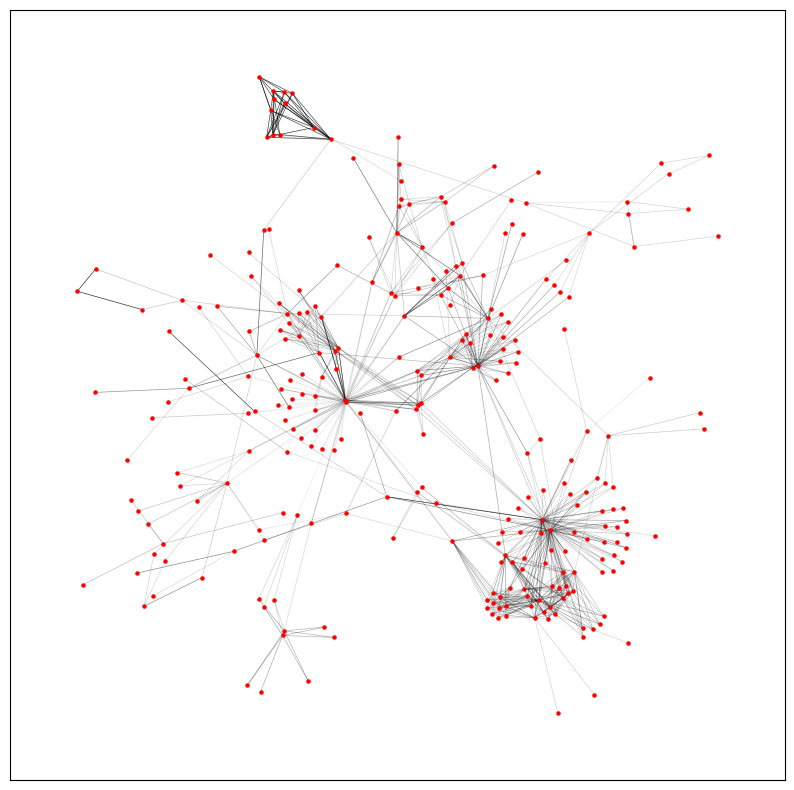

In [ ]:
pesos_aristas = [G_core[u][v]["prob"] for u, v,data in G_core.edges(data=True)]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_core,nx.spring_layout(G_core, seed=42,k=0.15),node_color="red",node_size=5)
nx.draw_networkx_edges(G_core,nx.spring_layout(G_core, seed=42,k=0.15),alpha=pesos_aristas,edge_color='black',width=0.5)#,arrowsize=5
plt.show()

In [ ]:
# 1. Guardar en formato GraphML (compatible con la mayoría de herramientas bioinformáticas)
nx.write_graphml(G_core, "grafo_proteinas_probabilista7.graphml")

print("¡Grafo guardado exitosamente en GraphML y GEXF!")

¡Grafo guardado exitosamente en GraphML y GEXF!
